In [107]:
cd ~/PycharmProjects/CleanSpace/momia2/

/Users/jzrolling/PycharmProjects/CleanSpace/momia2


In [108]:
import momia2 as mo
import os, glob, pandas as pd, numpy as np
import tifffile
from matplotlib import pyplot as plt
from scipy.stats import pearsonr
from IPython.display import display,clear_output
from joblib import Parallel, delayed
from skimage.registration import phase_cross_correlation
import seaborn as sns

In [109]:
sample_reference = pd.read_excel('/Volumes/ExtremePro/PMM_FTSZ_RAW/sample_reference.xlsx')
include = sample_reference[sample_reference['Include for analysis']==1].copy()

batch_dict = {}
for f in sorted(glob.glob('/Volumes/ExtremePro/PMM_FTSZ_RAW/BCG_FtsZ*/')):
    batch = f.split('/')[-2]
    if batch not in batch_dict:
        batch_dict[batch] = {}
    for seg_file in sorted(glob.glob(f+'*.pk')):
        if 'autosave__' in seg_file:
            well = seg_file.split('autosave__')[-1].split('_')[0]
        elif 'autosave' in seg_file:
            well = seg_file.split('autosave_')[-1].split('_')[0]
        else:
            well = seg_file.split('Well-')[-1].split('_')[0]
        
        if len(well)!=3:
            continue
        img_file = seg_file.replace('_seg.pk','.tif')
        if well not in batch_dict[batch]:
            batch_dict[batch][well] = [[img_file,seg_file]]
        else:
            batch_dict[batch][well] += [[img_file,seg_file]]

In [116]:
merged_cells = []

for batch, v in batch_dict.items():
    for well, well_files in v.items():
        cond1 = sample_reference['Batch']==batch
        cond2 = sample_reference['Well']==well
        ref_subset = sample_reference[(cond1)&(cond2)]
        if len(ref_subset)!=1:
            continue
        fold_mic, _include, cpd, group = ref_subset.values[0][-4:]

        pk_file = f'/Volumes/ExtremePro/PMM_FTSZ_filtered_output/{cpd}-{batch}-{well}.pk'
        df = mo.pickle_load(pk_file)
        
        if '20250828' not in batch:
            df[[f'log2_C{i}_mean' for i in range(5)]] = np.log2(df[[f'C{i}_mean' for i in range(5)]].values)
            df[[f'log2_C{i}_median' for i in range(5)]] = np.log2(df[[f'C{i}_median' for i in range(5)]].values)
            df[[f'log2_C{i}_max' for i in range(5)]] = np.log2(df[[f'C{i}_max' for i in range(5)]].values)
            df[[f'log2_C{i}_min' for i in range(5)]] = np.log2(df[[f'C{i}_min' for i in range(5)]].values)
            df[[f'log2_C{i}_Q1' for i in range(5)]] = np.log2(df[[f'C{i}_Q1' for i in range(5)]].values)
            df[[f'log2_C{i}_Q3' for i in range(5)]] = np.log2(df[[f'C{i}_Q3' for i in range(5)]].values)
            df[[f'log2_C{i}_std' for i in range(5)]] = np.log2(df[[f'C{i}_std' for i in range(5)]].values)
            df['C4-C2_diff'] = df['log2_C4_mean']-df['log2_C2_mean']
            df['Fold_mic'] = fold_mic
            df['log_Fold_mic'] = [-3 if x==0 else np.log2(x) for x in df['Fold_mic'].values]
        else:
            reordered_channels = [0,1,2,4,3] #to handle accidental swap of hada-nada channels
            df[[f'log2_C{i}_mean' for i in range(5)]] = np.log2(df[[f'C{i}_mean' for i in reordered_channels]].values)
            df[[f'log2_C{i}_median' for i in range(5)]] = np.log2(df[[f'C{i}_median' for i in reordered_channels]].values)
            df[[f'log2_C{i}_max' for i in range(5)]] = np.log2(df[[f'C{i}_max' for i in reordered_channels]].values)
            df[[f'log2_C{i}_min' for i in range(5)]] = np.log2(df[[f'C{i}_min' for i in reordered_channels]].values)
            df[[f'log2_C{i}_Q1' for i in range(5)]] = np.log2(df[[f'C{i}_Q1' for i in reordered_channels]].values)
            df[[f'log2_C{i}_Q3' for i in range(5)]] = np.log2(df[[f'C{i}_Q3' for i in reordered_channels]].values)
            df[[f'log2_C{i}_std' for i in range(5)]] = np.log2(df[[f'C{i}_std' for i in reordered_channels]].values)
            df[[f'C{i}_skewness' for i in range(5)]] = df[[f'C{i}_skewness' for i in reordered_channels]].values
            df[[f'C{i}_kurtosis' for i in range(5)]] = df[[f'C{i}_kurtosis' for i in reordered_channels]].values
            df['C4-C2_diff'] = df['log2_C4_mean']-df['log2_C2_mean']
            df['Fold_mic'] = fold_mic
            df['log_Fold_mic'] = [-3 if x==0 else np.log2(x) for x in df['Fold_mic'].values]
    
        if len(df)>100:
            df['Sample_UID'] = [f'{batch}_{well}' for batch, well in df[['Batch','Well']].values]
            merged_cells.append(df)

merged_cells = pd.concat(merged_cells).reset_index(drop=True)
mo.pickle_save(merged_cells,'/Volumes/ExtremePro/PMM_FTSZ_RAW/20260831_merged_cells.pk')

In [117]:
inshade_cols = ['InShaDe_{}'.format(x) for x in range(1,33)]
fl_val_cols = ['log2_C{}_{}'.format(c,s) for c in range(1,5) for s in ['mean','median','max','min','Q1','Q3']]
fl_stat_cols = ['C{}_{}'.format(c,s) for c in range(1,5) for s in ['CV','kurtosis','skewness']] + ['C4-C2_diff']
morph_cols = ['area','eccentricity','solidity','major_axis_length','minor_axis_length','extent',
              'moments_hu-0','moments_hu-1','moments_hu-2','moments_hu-3',
              'moments_hu-4','moments_hu-5','moments_hu-6','compactness','aspect_ratio','min_negative_curvature','max_positive_curvature','mean_curvature',
              'Q1_curvature','Q3_curvature','length [µm]','branched',
              'width_median [µm]','width_std [µm]','width_max [µm]','width_Q1 [µm]','width_Q3 [µm]',]

num_feature_cols = morph_cols + fl_val_cols
stat_feature_cols = inshade_cols + fl_stat_cols
all_feature_cols = num_feature_cols + stat_feature_cols
grouped_feature_cols = ['{}_{}'.format(c,feature) for c in ['MEAN','MEDIAN','SKEW','IQR','CV','Q1','Q3'] for feature in all_feature_cols ]+['Group_count']

In [120]:
grouped = merged_cells.groupby('Sample_UID')

# num_features
mean = grouped[all_feature_cols].mean().values
std =  grouped[all_feature_cols].std().values
median =  grouped[all_feature_cols].median().values
skew = grouped[all_feature_cols].skew().values
q1 = grouped[all_feature_cols].quantile(0.25).values
q3 = grouped[all_feature_cols].quantile(0.75).values
iqr = q3-q1
cv = std/mean
counts = grouped.count()

grouped_features = np.hstack([mean,median,skew,iqr,cv,q1,q3,counts.values[:,0].reshape(-1,1)])
grouped_df = grouped[['Batch','Well','Fold_mic','log_Fold_mic','Compound','Group']].agg('first')
grouped_df = pd.concat([grouped_df, 
                        pd.DataFrame(grouped_features,columns=grouped_feature_cols,index=grouped_df.index)],axis=1)
grouped_df['Sample_UID'] = grouped_df.index
grouped_df = grouped_df.reset_index(drop=True)
mo.pickle_save(grouped_df,'/Users/jzrolling/Desktop/Projects/GHDDI/FtsZ_manuscript/20260831_merged_grouped.pk')

In [121]:
merged_grouped = mo.pickle_load('/Users/jzrolling/Desktop/Projects/GHDDI/FtsZ_manuscript/20260831_merged_grouped.pk')
merged_cells = mo.pickle_load('/Volumes/ExtremePro/PMM_FTSZ_RAW/20260831_merged_cells.pk')

In [122]:
# define batch-wise internal controls
control_uid_dict = {}
for b in merged_grouped['Batch'].unique():
    subset = merged_grouped[merged_grouped['Batch']==b].copy()
    if 'daysinduction' in b:
        control = subset[(subset['Fold_mic']<=0.5) & (subset['Group']=='FtsZ-Ctrl')]
    else:
        control = subset[subset['Fold_mic']==0]
    if len(control)==1:
        control = subset[subset['Fold_mic']<=0.25]
    control_uid_dict[b] = control['Sample_UID'].values    

# define features subjecting to znorm
morph_cols = ['area','eccentricity','solidity','major_axis_length','minor_axis_length','extent',
              'moments_hu-0','moments_hu-1','moments_hu-2','moments_hu-3',
              'moments_hu-4','moments_hu-5','moments_hu-6','compactness','aspect_ratio','min_negative_curvature','max_positive_curvature','mean_curvature',
              'Q1_curvature','Q3_curvature','length [µm]',
              'width_median [µm]','width_std [µm]','width_max [µm]','width_Q1 [µm]','width_Q3 [µm]',]

inshade_cols = ['InShaDe_{}'.format(x) for x in range(1,33)]
fl_val_cols = ['log2_C{}_{}'.format(c,s) for c in range(1,5) for s in ['mean','median','max','min','Q1','Q3']]
fl_stat_cols = ['C{}_{}'.format(c,s) for c in range(1,5) for s in ['CV','kurtosis','skewness']] + ['C4-C2_diff']
z_norm_cols = morph_cols + inshade_cols + fl_val_cols + fl_stat_cols

# run batch-wise cell normalization
batch_znorm = []
for b in merged_grouped['Batch'].unique():
    subset = merged_cells[merged_cells['Batch']==b].copy()
    control_uids = control_uid_dict[b]
    control_cells = merged_cells[merged_cells['Sample_UID'].isin(control_uids)].copy()
    control_mean = control_cells[z_norm_cols].mean().values
    control_std = control_cells[z_norm_cols].std().values
    subset[z_norm_cols] = (subset[z_norm_cols].values-control_mean[np.newaxis,:])/control_std[np.newaxis,:]
    batch_znorm.append(subset)
batch_znorm = pd.concat(batch_znorm)
mo.pickle_save(batch_znorm, '/Volumes/ExtremePro/PMM_FTSZ_RAW/20260901_znorm_merged_cells.pk')

In [123]:
grouped = batch_znorm.groupby('Sample_UID')

# num_features
mean = grouped[all_feature_cols].mean().values
std =  grouped[all_feature_cols].std().values
median =  grouped[all_feature_cols].median().values
skew = grouped[all_feature_cols].skew().values
q1 = grouped[all_feature_cols].quantile(0.25).values
q3 = grouped[all_feature_cols].quantile(0.75).values
iqr = q3-q1
cv = std/mean
counts = grouped.count()

grouped_features = np.hstack([mean,median,skew,iqr,cv,q1,q3,counts.values[:,0].reshape(-1,1)])
grouped_df = grouped[['Batch','Well','Fold_mic','log_Fold_mic','Compound','Group']].agg('first')
grouped_df = pd.concat([grouped_df, 
                        pd.DataFrame(grouped_features,columns=grouped_feature_cols,index=grouped_df.index)],axis=1)
grouped_df['Sample_UID'] = grouped_df.index
grouped_df = grouped_df.reset_index(drop=True)
mo.pickle_save(grouped_df,'/Users/jzrolling/Desktop/Projects/GHDDI/FtsZ_manuscript/20260901_batchnorm_merged_grouped.pk')

In [124]:
merged_grouped = mo.pickle_load('/Users/jzrolling/Desktop/Projects/GHDDI/FtsZ_manuscript/20260901_batchnorm_merged_grouped.pk')

/var/folders/1y/_2nhqmfd56s2k1hktst6p9b80000gn/T/ipykernel_96670/2278528193.py:16: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig=plt.figure(figsize=(4,4))


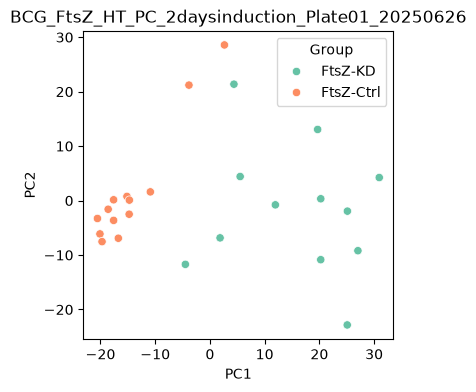

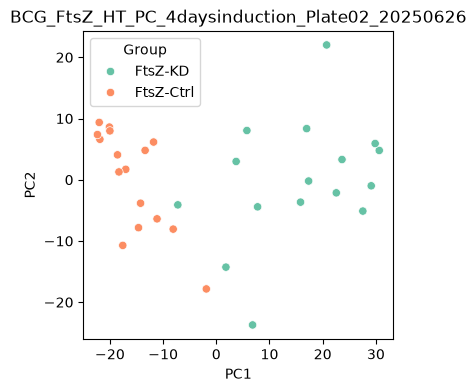

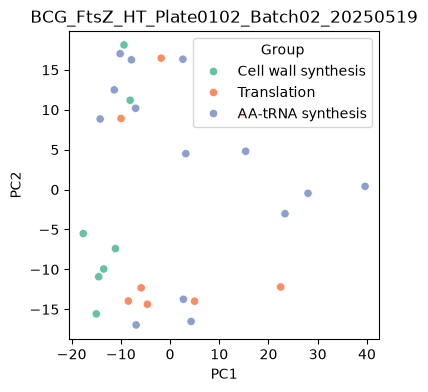

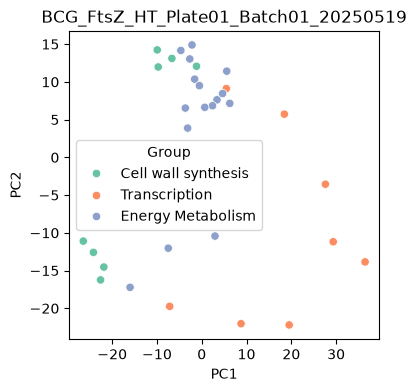

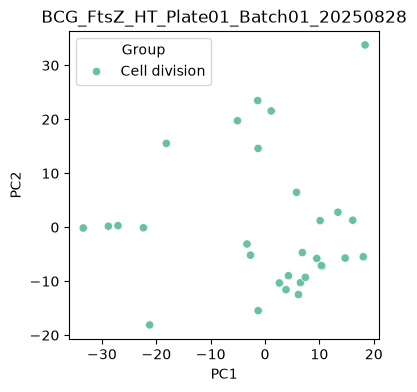

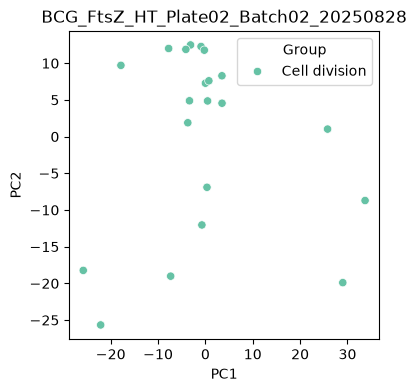

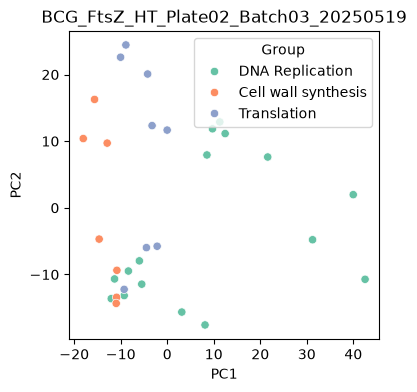

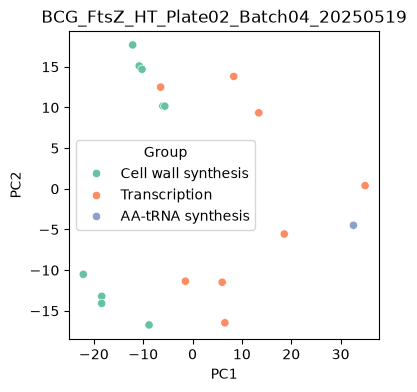

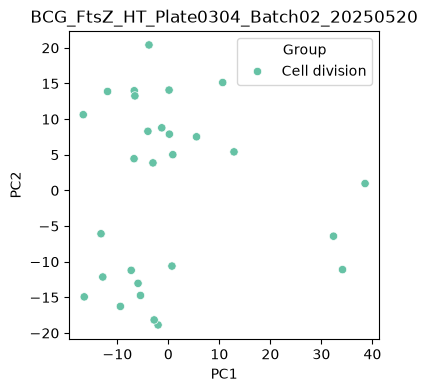

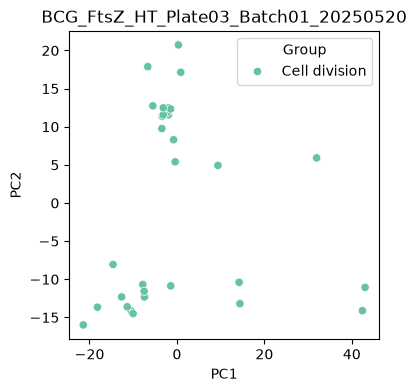

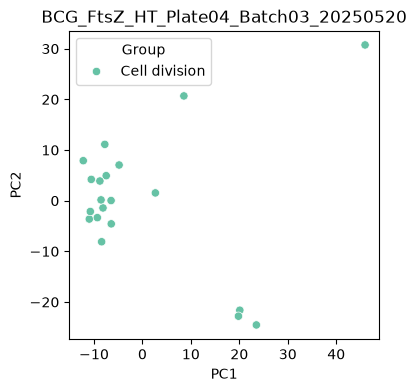

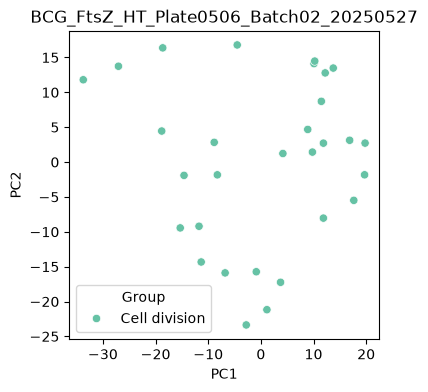

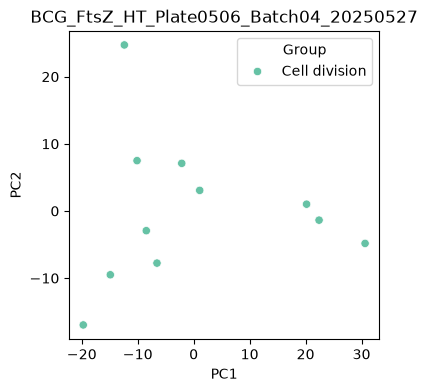

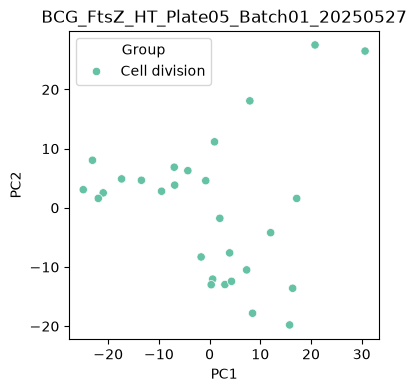

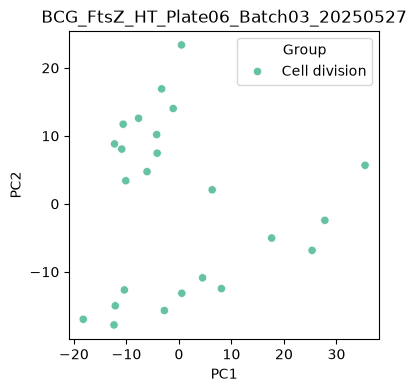

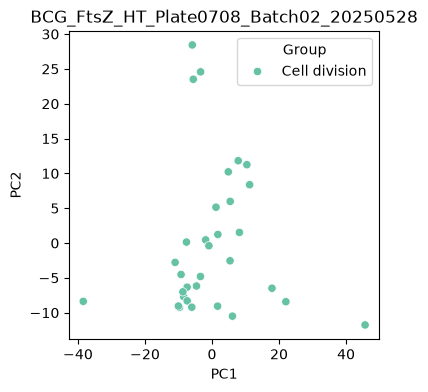

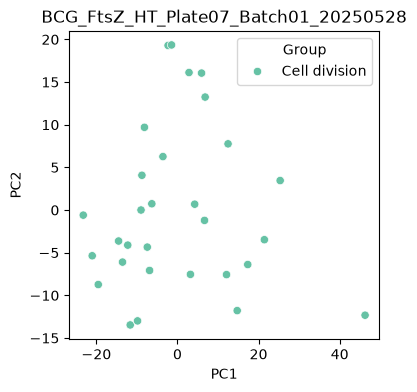

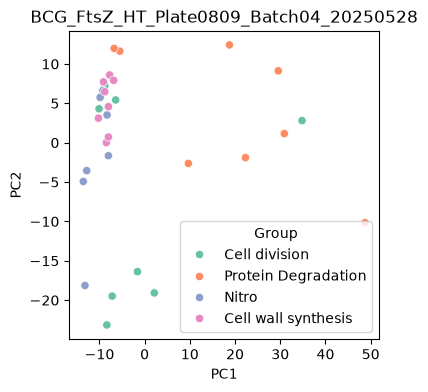

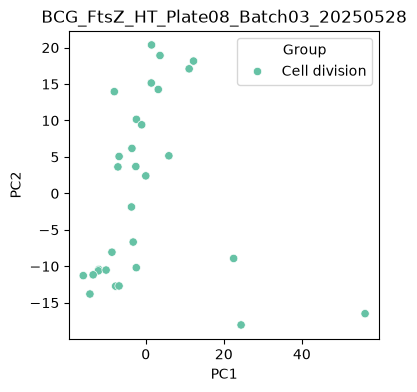

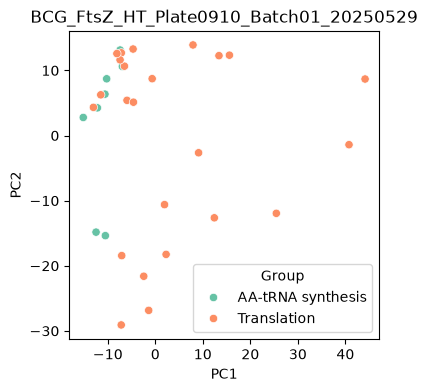

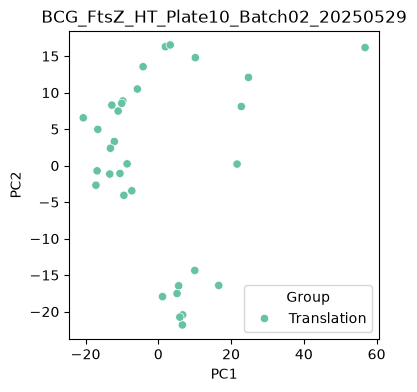

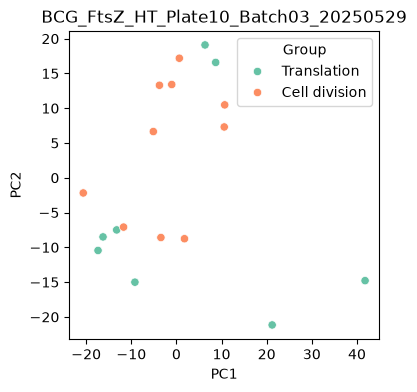

In [125]:
from umap import UMAP
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
#merged_grouped = grouped_df
#1 batch normalization
for b in merged_grouped['Batch'].unique():
    subset = merged_grouped[merged_grouped['Batch']==b].copy()
    vals = subset[grouped_feature_cols].values.astype(float)
    isnan_ids = np.unique(np.where(np.isnan(vals))[1])
    isinf_ids = np.unique(np.where(np.isinf(vals))[1])
    valid_cols = np.array([x for x in range(vals.shape[1]) if x not in np.hstack([isnan_ids,isinf_ids])])
    vals_filtered = vals[:, valid_cols]
    norm = StandardScaler().fit_transform(vals_filtered)
    pc = PCA(n_components=2).fit_transform(norm)
    subset[['PC1','PC2']] = pc
    fig=plt.figure(figsize=(4,4))
    ax=fig.add_subplot()
    sns.scatterplot(data=subset,x='PC1',y='PC2',hue='Group',palette='Set2')
    ax.set_title(b)

/Users/jzrolling/miniconda3/envs/tensorflow_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


"\nfor d1,d2,drug,mic in subset[['PaCMAP-1','PaCMAP-2','Compound','Fold_mic']].values:\n    #t = '{}x\n{}'.format(mic,drug)\n    t = drug\n    ax.text(d1,d2,t,fontsize=5,ha='center',va='center',zorder=6)\nplt.legend(loc=(1.02,0.5))\n"

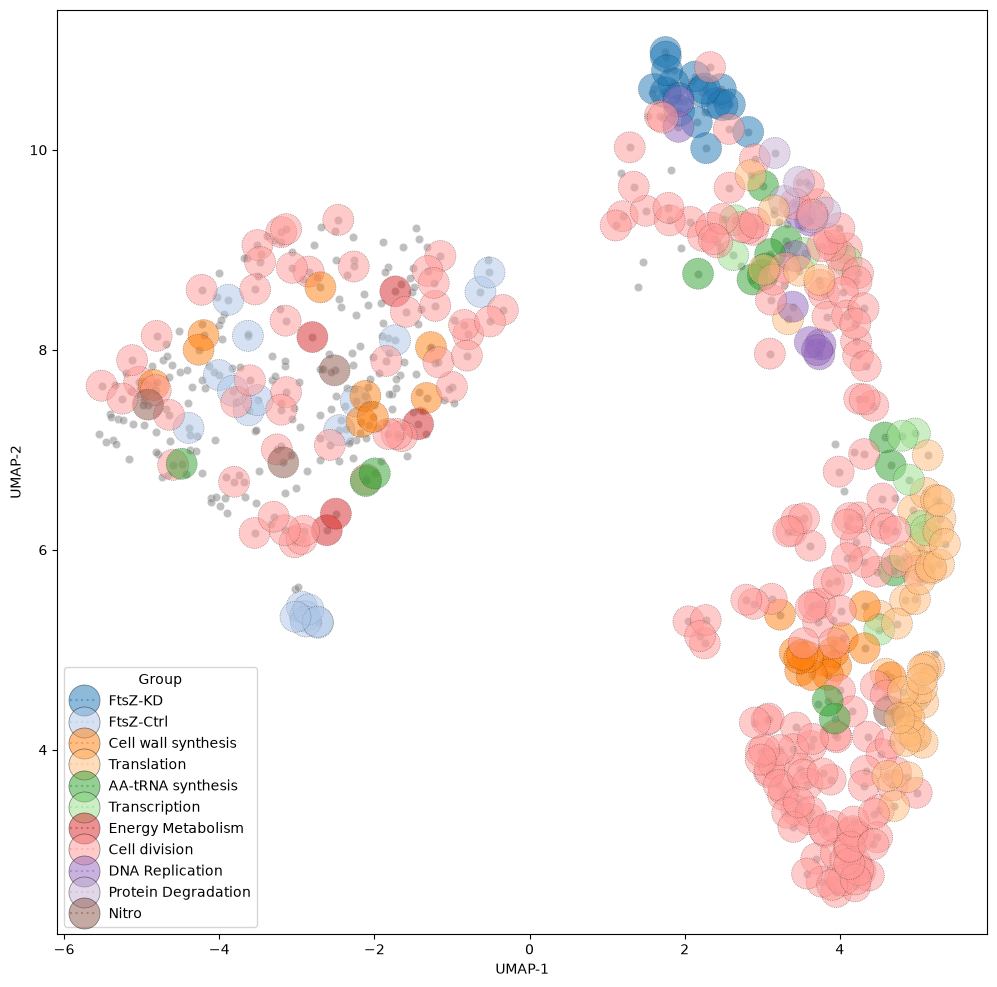

In [126]:
inshade_cols = ['InShaDe_{}'.format(x) for x in range(1,33)]
fl_val_cols = ['log2_C{}_{}'.format(c,s) for c in range(1,5) for s in ['mean','median','max','min','Q1','Q3']]
fl_stat_cols = ['C{}_{}'.format(c,s) for c in range(1,5) for s in ['CV','kurtosis','skewness']] + ['C4-C2_diff']
morph_cols = ['area','eccentricity','solidity','major_axis_length','minor_axis_length','extent',
              'moments_hu-0','moments_hu-1','moments_hu-2','moments_hu-3',
              'moments_hu-4','moments_hu-5','moments_hu-6','compactness','aspect_ratio','min_negative_curvature','max_positive_curvature','mean_curvature',
              'Q1_curvature','Q3_curvature','length [µm]','branched',
              'width_median [µm]','width_std [µm]','width_max [µm]','width_Q1 [µm]','width_Q3 [µm]',]

num_feature_cols = morph_cols + fl_val_cols
stat_feature_cols = inshade_cols + fl_stat_cols
all_feature_cols = num_feature_cols + stat_feature_cols 
grouped_feature_cols = ['{}_{}'.format(c,feature) for c in ['MEAN','MEDIAN','IQR','CV','SKEW'] for feature in all_feature_cols]

vals = merged_grouped[grouped_feature_cols].values.astype(float)
isnan_ids = np.unique(np.where(np.isnan(vals))[1])
isinf_ids = np.unique(np.where(np.isinf(vals))[1])
valid_cols = np.array([x for x in range(vals.shape[1]) if x not in np.hstack([isnan_ids,isinf_ids])])
vals_filtered = vals[:, valid_cols]

norm = StandardScaler().fit_transform(vals_filtered)
pc = PCA(n_components=2).fit_transform(norm)


n_components = 2
umap = UMAP(n_components=n_components, n_jobs=-1, n_neighbors=30,
            min_dist=0.2,
            metric='cosine',random_state=12,spread=1)
u = umap.fit_transform(norm)

merged_grouped[['PC1','PC2']] = pc
merged_grouped[[f'UMAP-{x+1}' for x in range(n_components)]] =u

fig=plt.figure(figsize=(12,12))
ax=fig.add_subplot()
sns.scatterplot(data=merged_grouped,x='UMAP-1',y='UMAP-2',color='grey',alpha=0.5)
subset = merged_grouped[(merged_grouped['Group']!='Unknown')&\
                        (merged_grouped['Compound']!='Streptomycin')&\
                        (merged_grouped['Compound']!='BDQ')&\
                        (merged_grouped['Fold_mic']>=1)]
sns.scatterplot(data=subset,x='UMAP-1',y='UMAP-2',hue='Group', 
                palette='tab20',s=500,alpha=0.5,legend=True,ec='black',lw=0.5,ls=':',
                zorder=5)

#sns.scatterplot(data=grouped_data[grouped_data['Compound']=='SRI-3072'],x='UMAP-1',y='UMAP-2',hue='Fold_MIC',
#                palette='coolwarm',s=100)
"""
for d1,d2,drug,mic in subset[['PaCMAP-1','PaCMAP-2','Compound','Fold_mic']].values:
    #t = '{}x\n{}'.format(mic,drug)
    t = drug
    ax.text(d1,d2,t,fontsize=5,ha='center',va='center',zorder=6)
plt.legend(loc=(1.02,0.5))
"""
#plt.savefig(outfolder+'20250829_BCG_BCP.png',dpi=350,bbox_inches='tight')

/var/folders/1y/_2nhqmfd56s2k1hktst6p9b80000gn/T/ipykernel_96670/2081585481.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_yticklabels([x.get_text() for x in axes[i].get_yticklabels()],fontname='Arial',fontsize=10);
/var/folders/1y/_2nhqmfd56s2k1hktst6p9b80000gn/T/ipykernel_96670/2081585481.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_yticklabels([x.get_text() for x in axes[i].get_yticklabels()],fontname='Arial',fontsize=10);
/var/folders/1y/_2nhqmfd56s2k1hktst6p9b80000gn/T/ipykernel_96670/2081585481.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_yticklabels([x.get_text() for x

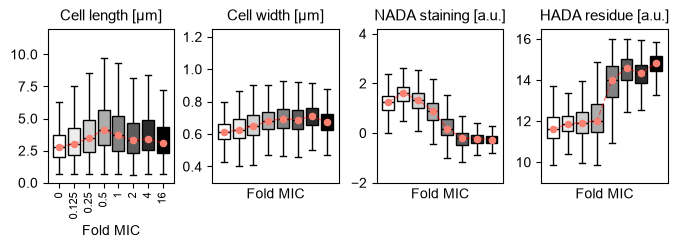

In [235]:
fig,axes = plt.subplots(figsize=(8,2),ncols=4,gridspec_kw={'wspace':0.3})
features = ['length [µm]','width_median [µm]','C4-C2_diff','log2_C3_mean']
drug = 'RIF'
subset = merged_cells[merged_cells['Compound']==drug].copy()
grouped = subset.groupby('log_Fold_mic')
drange = [[0,12],[0.3,1.25],[-2,4.2],[9,16.5]]
titles = ['Cell length [µm]','Cell width [µm]','NADA staining [a.u.]','HADA residue [a.u.]']
for i,f in enumerate(features):
    sns.boxplot(data=subset,x='log_Fold_mic',y=f,hue='log_Fold_mic',
                palette='Greys',ax=axes[i],legend=False,fliersize=0)
    grouped_v = grouped[f].median()
    axes[i].set_ylim(drange[i][0],drange[i][1])
    axes[i].set_ylabel('')
    axes[i].set_xlabel('')
    axes[i].set_xticks([])
    axes[i].set_title(titles[i],fontname='Arial',fontsize=11) 
    axes[i].set_yticklabels([x.get_text() for x in axes[i].get_yticklabels()],fontname='Arial',fontsize=10);
    axes[i].plot(np.arange(8),grouped_v.values,zorder=3,lw=1,color='r',alpha=0.5,ls='--')
    axes[i].scatter(np.arange(8),grouped_v.values,zorder=3,lw=1,color='salmon',s=20,alpha=1)
    if i==0:
        axes[i].set_xticks(np.arange(8))
        axes[i].set_xticklabels([0,0.125,0.25,0.5,1,2,4,16],fontname='Arial',fontsize=8,rotation=90)
    axes[i].set_xlabel('Fold MIC',fontname='Arial',fontsize=10)
plt.savefig('/Users/jzrolling/Desktop/Projects/GHDDI/FtsZ_manuscript/Figures/RIF_dynamics.svg',bbox_inches='tight')

/var/folders/1y/_2nhqmfd56s2k1hktst6p9b80000gn/T/ipykernel_96670/3075798259.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_yticklabels([x.get_text() for x in axes[i].get_yticklabels()],fontname='Arial',fontsize=10);
/var/folders/1y/_2nhqmfd56s2k1hktst6p9b80000gn/T/ipykernel_96670/3075798259.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_yticklabels([x.get_text() for x in axes[i].get_yticklabels()],fontname='Arial',fontsize=10);
/var/folders/1y/_2nhqmfd56s2k1hktst6p9b80000gn/T/ipykernel_96670/3075798259.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_yticklabels([x.get_text() for x

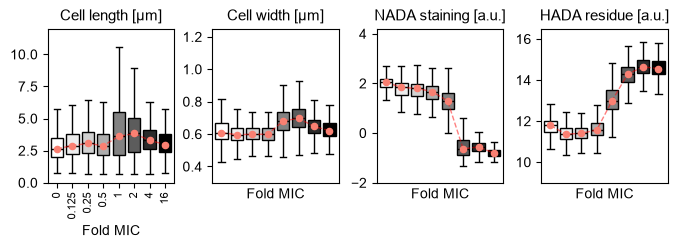

In [238]:
fig,axes = plt.subplots(figsize=(8,2),ncols=4,gridspec_kw={'wspace':0.3})
features = ['length [µm]','width_median [µm]','C4-C2_diff','log2_C3_mean']
drug = 'TBC47'
subset = merged_cells[merged_cells['Compound']==drug].copy()
grouped = subset.groupby('log_Fold_mic')
drange = [[0,12],[0.3,1.25],[-2,4.2],[9,16.5]]
titles = ['Cell length [µm]','Cell width [µm]','NADA staining [a.u.]','HADA residue [a.u.]']
for i,f in enumerate(features):
    sns.boxplot(data=subset,x='log_Fold_mic',y=f,hue='log_Fold_mic',
                palette='Greys',ax=axes[i],legend=False,fliersize=0)
    grouped_v = grouped[f].median()
    axes[i].set_ylim(drange[i][0],drange[i][1])
    axes[i].set_ylabel('')
    axes[i].set_xlabel('')
    axes[i].set_xticks([])
    axes[i].set_title(titles[i],fontname='Arial',fontsize=11) 
    axes[i].set_yticklabels([x.get_text() for x in axes[i].get_yticklabels()],fontname='Arial',fontsize=10);
    axes[i].set_xlim(-0.6,7.6)
    axes[i].plot(np.arange(8),grouped_v.values,zorder=3,lw=1,color='r',alpha=0.5,ls='--')
    axes[i].scatter(np.arange(8),grouped_v.values,zorder=3,lw=1,color='salmon',s=20,alpha=1)
    if i==0:
        axes[i].set_xticks(np.arange(8))
        axes[i].set_xticklabels([0,0.125,0.25,0.5,1,2,4,16],fontname='Arial',fontsize=8,rotation=90)
    axes[i].set_xlabel('Fold MIC',fontname='Arial',fontsize=10)
plt.savefig('/Users/jzrolling/Desktop/Projects/GHDDI/FtsZ_manuscript/Figures/TBC47_dynamics.svg',bbox_inches='tight')

In [317]:
from microfilm.microplot import microshow
rif_demo = sorted(glob.glob('/Users/jzrolling/Desktop/Projects/GHDDI/FtsZ_manuscript/Figures/RIF_demo/*.tif'))[::-1]
tbc47_demo = sorted(glob.glob('/Users/jzrolling/Desktop/Projects/GHDDI/FtsZ_manuscript/Figures/TBC47_demo/*.tif'))[::-1]
gh161_demo = sorted(glob.glob('/Users/jzrolling/Desktop/Projects/GHDDI/FtsZ_manuscript/Figures/GH161_demo/*.tif'))[::-1]
for i,imgf in enumerate(rif_demo):
    if i==1:
        ch3_lim = [10000,30000]
    else:
        ch3_lim = [10000,50000]
    fig,axes = plt.subplots(figsize=(8,8),nrows=2,ncols=2,gridspec_kw={'hspace':0.02,'wspace':0.02})
    img = tifffile.imread(imgf)
    g1 = microshow(img[0],limits=[1000,16000],ax=axes[0,0],cmaps='gist_grey')
    g2 = microshow(img[3],limits=ch3_lim,ax=axes[0,1],cmaps='pure_cyan')
    ch4 = mo.utils.subtract_background(img[4]).astype(float)
    ch2 = mo.utils.subtract_background(img[2]).astype(float)
    dif = ch4-ch2
    dif[dif<0] = 0
    g3 = microshow(dif,limits=[0,15000],ax=axes[1,0],cmaps='pure_magenta')
    
    g4 = microshow([img[0],img[3],dif],limits=[[1000,16000],ch3_lim,[0,15000]],
                   ax=axes[1,1],cmaps=['gist_grey','pure_cyan','pure_magenta'],
                   scalebar_unit_per_pix=0.065,unit='um',scalebar_size_in_units=5,scalebar_font_size=0)
    outname = imgf.replace('.tif','_demo.svg')
    plt.savefig(outname,bbox_inches='tight',dpi=300)
    plt.close()

for i,imgf in enumerate(tbc47_demo):
    if i==0:
        ch3_lim = [10000,30000]
    else:
        ch3_lim = [10000,50000]
    fig,axes = plt.subplots(figsize=(8,8),nrows=2,ncols=2,gridspec_kw={'hspace':0.02,'wspace':0.02})
    img = tifffile.imread(imgf)
    g1 = microshow(img[0],limits=[2000,25000],ax=axes[0,0],cmaps='gist_grey')
    g2 = microshow(img[3],limits=ch3_lim,ax=axes[0,1],cmaps='pure_cyan')
    ch4 = mo.utils.subtract_background(img[4]).astype(float)
    ch2 = mo.utils.subtract_background(img[2]).astype(float)
    dif = ch4-ch2
    dif[dif<0] = 0
    g3 = microshow(dif,limits=[0,15000],ax=axes[1,0],cmaps='pure_magenta')
    
    g4 = microshow([img[0],img[3],dif],limits=[[2000,25000],ch3_lim,[0,15000]],
                   ax=axes[1,1],cmaps=['gist_grey','pure_cyan','pure_magenta'],
                   scalebar_unit_per_pix=0.065,unit='um',scalebar_size_in_units=5,scalebar_font_size=0)
    outname = imgf.replace('.tif','_demo.svg')
    plt.savefig(outname,bbox_inches='tight',dpi=300)
    plt.close()

for i,imgf in enumerate(gh161_demo):
    if i==1:
        ch3_lim = [10000,30000]
    else:
        ch3_lim = [10000,30000]
    fig,axes = plt.subplots(figsize=(8,8),nrows=2,ncols=2,gridspec_kw={'hspace':0.02,'wspace':0.02})
    img = tifffile.imread(imgf)
    g1 = microshow(img[0],limits=[2000,18000],ax=axes[0,0],cmaps='gist_grey')
    g2 = microshow(img[3],limits=ch3_lim,ax=axes[0,1],cmaps='pure_cyan')
    ch4 = mo.utils.subtract_background(img[4]).astype(float)
    ch2 = mo.utils.subtract_background(img[2]).astype(float)
    dif = ch4-ch2
    dif[dif<0] = 0
    g3 = microshow(dif,limits=[0,15000],ax=axes[1,0],cmaps='pure_magenta')
    
    g4 = microshow([img[0],img[3],dif],limits=[[2000,18000],ch3_lim,[0,15000]],
                   ax=axes[1,1],cmaps=['gist_grey','pure_cyan','pure_magenta'],
                   scalebar_unit_per_pix=0.065,unit='um',scalebar_size_in_units=5,scalebar_font_size=0)
    outname = imgf.replace('.tif','_demo.svg')
    plt.savefig(outname,bbox_inches='tight',dpi=300)
    plt.close()
    

/var/folders/1y/_2nhqmfd56s2k1hktst6p9b80000gn/T/ipykernel_96670/3826500568.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_yticklabels([x.get_text() for x in axes[i].get_yticklabels()],fontname='Arial',fontsize=10);
/var/folders/1y/_2nhqmfd56s2k1hktst6p9b80000gn/T/ipykernel_96670/3826500568.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_yticklabels([x.get_text() for x in axes[i].get_yticklabels()],fontname='Arial',fontsize=10);
/var/folders/1y/_2nhqmfd56s2k1hktst6p9b80000gn/T/ipykernel_96670/3826500568.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_yticklabels([x.get_text() for x

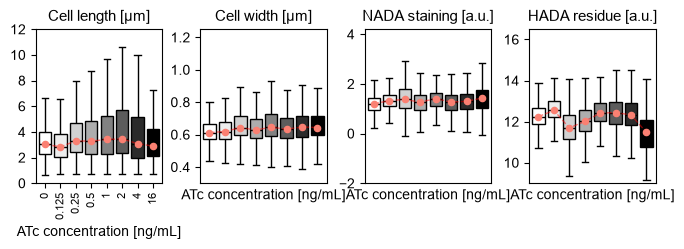

In [314]:
fig,axes = plt.subplots(figsize=(8,2),ncols=4,gridspec_kw={'wspace':0.3})
features = ['length [µm]','width_median [µm]','C4-C2_diff','log2_C3_mean']
drug = 'GH161-96hrs-Rep1'
subset = merged_cells[merged_cells['Compound']==drug].copy()
grouped = subset.groupby('log_Fold_mic')
drange = [[0,12],[0.3,1.25],[-2,4.2],[9,16.5]]
titles = ['Cell length [µm]','Cell width [µm]','NADA staining [a.u.]','HADA residue [a.u.]']
for i,f in enumerate(features):
    sns.boxplot(data=subset,x='log_Fold_mic',y=f,hue='log_Fold_mic',
                palette='Greys',ax=axes[i],legend=False,fliersize=0)
    grouped_v = grouped[f].median()
    axes[i].set_ylim(drange[i][0],drange[i][1])
    axes[i].set_ylabel('')
    axes[i].set_xlabel('')
    axes[i].set_xticks([])
    axes[i].set_title(titles[i],fontname='Arial',fontsize=11) 
    axes[i].set_yticklabels([x.get_text() for x in axes[i].get_yticklabels()],fontname='Arial',fontsize=10);
    axes[i].set_xlim(-0.6,7.6)
    axes[i].plot(np.arange(8),grouped_v.values,zorder=3,lw=1,color='r',alpha=0.5,ls='--')
    axes[i].scatter(np.arange(8),grouped_v.values,zorder=3,lw=1,color='salmon',s=20,alpha=1)
    if i==0:
        axes[i].set_xticks(np.arange(8))
        axes[i].set_xticklabels([0,0.125,0.25,0.5,1,2,4,16],fontname='Arial',fontsize=8,rotation=90)
    axes[i].set_xlabel('ATc concentration [ng/mL]',fontname='Arial',fontsize=10)
plt.savefig('/Users/jzrolling/Desktop/Projects/GHDDI/FtsZ_manuscript/Figures/GH161_dynamics.svg',bbox_inches='tight')